In [1]:
from helpers import *
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib as mpl
mpl.rcParams['text.usetex'] = True
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.size'] = 14
plt.rcParams['mathtext.fontset'] = 'stix'  # Use STIX fonts for math symbols

color_surface = 'PuOr_r'
color_S = 'r'
color_stream = 'gray'
color_u = 'k'

Select five typical ECS
- EQ: $WF^1$ (stable, collective instability bifurcated from $VEM^1$)
- EQ: $IWF^1$ (stable,collective instability bifurcated from $IEM^1$)
- TW: $TM_1$ (unstable, downward traveling wave of modons)
- PO: $PO_3$ (unstable, PO bifurcated from $VEM^2$)
- RPO: $RPO_2$ (stable, RPO bifurcated from $IEM^2$)

# Generate video for presentation

In [2]:
data_index = {
    'a': ('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.4_WF/', r'($a$)', 0.4, 0.2, False),
    'b': ('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.4_IWF/', r'($b$)', 0.4, 0.6, False),
    'c': ('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_TM1/', r'($c$)', 0.6, 0.1, True),
    'd': ('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.8_PO3/', r'($d$)', 0.8, 0.2, True),
    'e': ('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.8_RPO2/', r'($e$)', 0.8, 0.6, True),
}


def load_time_dependent_solution(filename):
    with h5py.File(filename, mode='r') as file:
        x_key = [k for k in file['scales'].keys() if k.startswith('x_hash')][0]
        x = file[f'scales/{x_key}'][:]        # usually shape (Nz, 1, 1)
        x = np.squeeze(x)
        z_key = [k for k in file['scales'].keys() if k.startswith('z_hash')][0]
        z = file[f'scales/{z_key}'][:]        # usually shape (Nz, 1, 1)
        z = np.squeeze(z) 
        time = file['scales/sim_time']
        u = file['tasks']['u'][:,0,:,:]
        w = file['tasks']['u'][:,1,:,:]
        t = file['tasks']['te']
        s = file['tasks']['sa']
        u = np.array(u).real
        # print(f'shape u= {np.shape(u)}')
        w = np.array(w).real
        t = np.array(t).real
        s = np.array(s).real
        time = np.array(time)
        # print(f'shape s= {np.shape(s)}')
        return(x,z,t,s,u,w,time)


FFmpeg Available: True


C:\Users\jms24002\AppData\Local\Temp\ipykernel_31224\1757124208.py:113: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


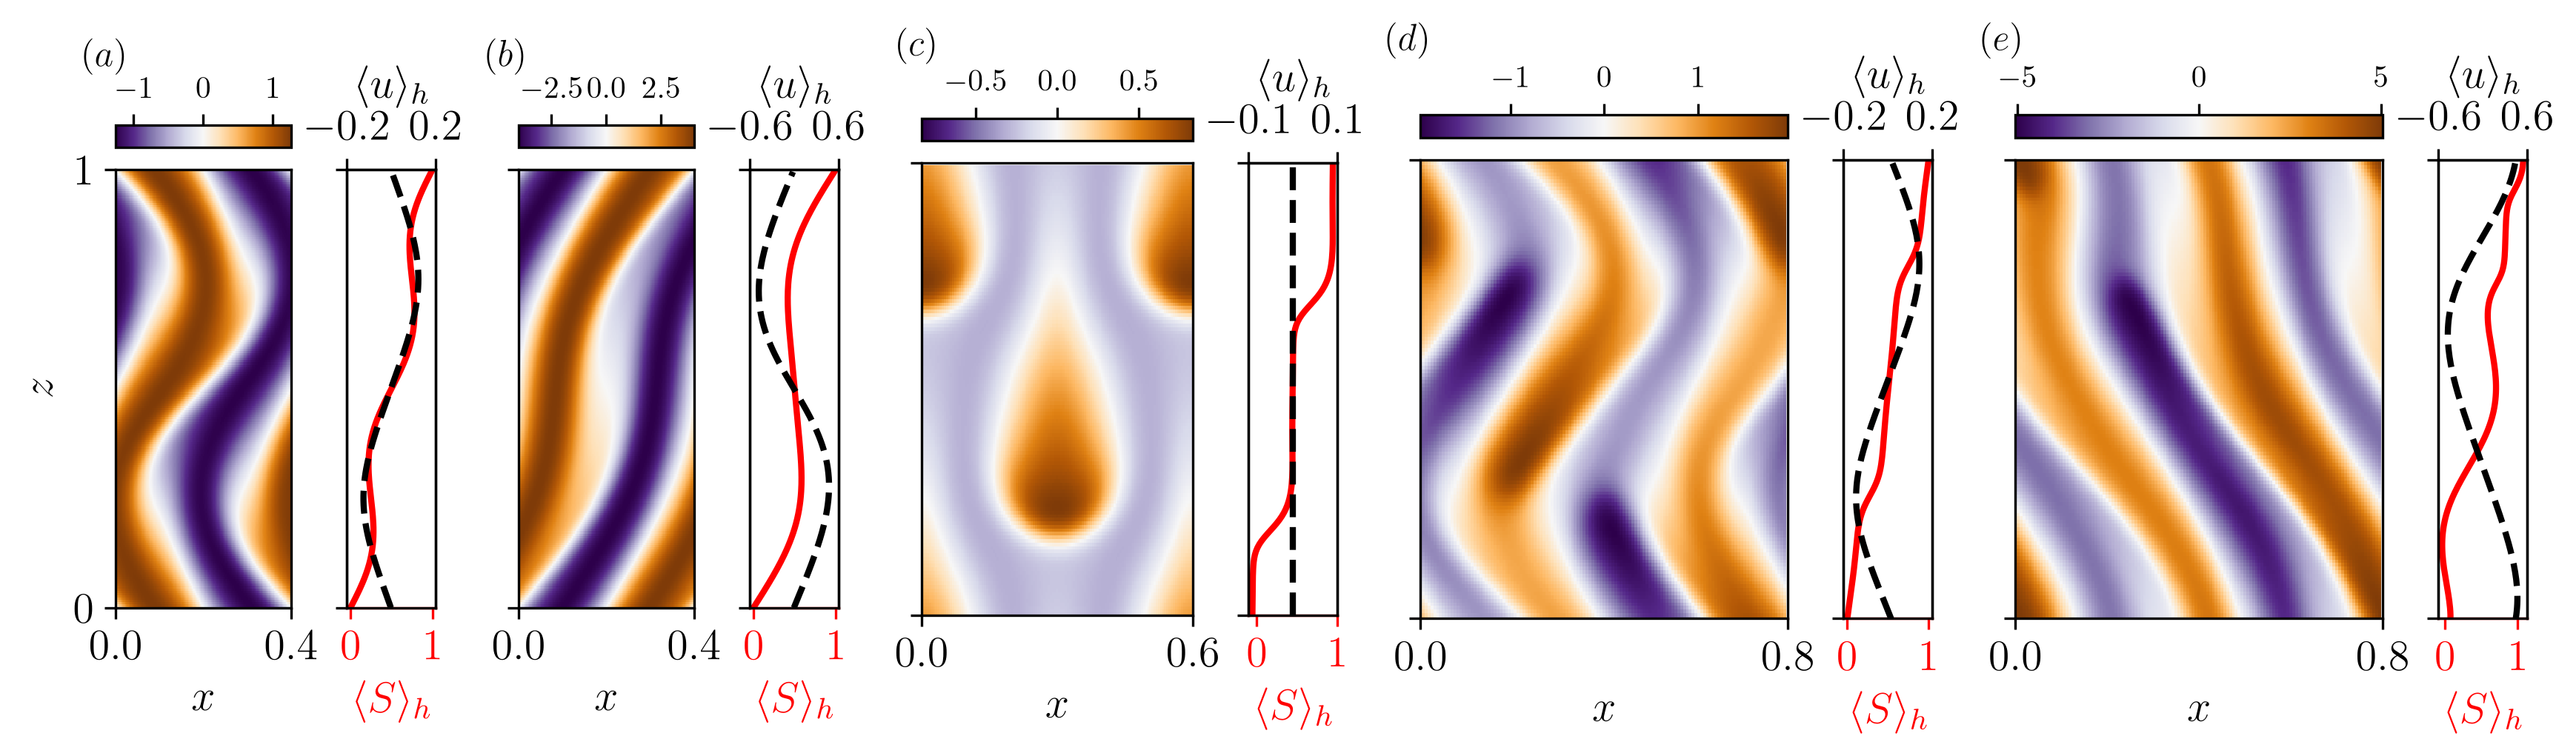

nframes =  200
Updating frame 0
Updating frame 0
Updating frame 1
Updating frame 2
Updating frame 3
Updating frame 4
Updating frame 5
Updating frame 6
Updating frame 7
Updating frame 8
Updating frame 9
Updating frame 10
Updating frame 11
Updating frame 12
Updating frame 13
Updating frame 14
Updating frame 15
Updating frame 16
Updating frame 17
Updating frame 18
Updating frame 19
Updating frame 20
Updating frame 21
Updating frame 22
Updating frame 23
Updating frame 24
Updating frame 25
Updating frame 26
Updating frame 27
Updating frame 28
Updating frame 29
Updating frame 30
Updating frame 31
Updating frame 32
Updating frame 33
Updating frame 34
Updating frame 35
Updating frame 36
Updating frame 37
Updating frame 38
Updating frame 39
Updating frame 40
Updating frame 41
Updating frame 42
Updating frame 43
Updating frame 44
Updating frame 45
Updating frame 46
Updating frame 47
Updating frame 48
Updating frame 49
Updating frame 50
Updating frame 51
Updating frame 52
Updating frame 53
Updati

In [3]:
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.animation as animation
from matplotlib.animation import FuncAnimation
from matplotlib.animation import FFMpegWriter

# Check if Matplotlib already sees FFmpeg
if not animation.FFMpegWriter.isAvailable():
    try:
        import imageio_ffmpeg

        # Connect imageio-ffmpeg executable to Matplotlib
        plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
    except ImportError:
        print("imageio-ffmpeg is not installed. Run: %pip install imageio-ffmpeg")

# Verify connection
print("FFmpeg Available:", animation.FFMpegWriter.isAvailable())

# Adjust figure size for a single-column or wide-column PRL layout
fig = plt.figure(figsize=(14, 3.5),dpi=300) 
# width_ratios should ideally match your Lx values for consistency
gs = gridspec.GridSpec(1, 5, width_ratios=[0.5, 0.5, 0.65, 0.8, 0.8], wspace=0.2)
axes = [fig.add_subplot(gs[0, i]) for i in range(5)]

field_pointers = np.zeros_like(axes, dtype=None)
streamline_pointers = np.zeros_like(axes, dtype=None)
u_pointers = np.zeros_like(axes, dtype=None)
s_pointers = np.zeros_like(axes, dtype=None)

    
for i, ax in enumerate(axes):
    label_name, (path, label, Lx, u_max, motion) = list(data_index.items())[i]
    if motion == False:
        [x, z, t, s, u, w] = return_fields(path+'solution.nc')
    else:
        [x, z, t, s, u, w, time] = load_time_dependent_solution(path+'snapshots/snapshots_s1.h5')
        # print(f"u shape before: {u.shape}") 
        t = t[0]
        s = s[0]
        u = u[0]
        w = w[0]

    smin = np.min(s)
    smax = np.max(s)
    max_abs = max(abs(smin), abs(smax))

    # Plot Field
    X, Z = np.meshgrid(x, z)
    # print(f"X shape: {X.shape}, Z shape: {Z.shape}")
    # print(f"s shape before: {s.shape}") 
    field_pointers[i] = ax.pcolormesh(X, Z, s.T,vmin=-max_abs,vmax=max_abs, cmap=color_surface, shading='auto')
    # streamline_pointers[i] = ax.streamplot(X, Z, u.T, w.T, color=color_stream, density=0.6, linewidth=0.5, arrowsize=1)
    
    # Format Main Axis
    ax.set_xlabel('$x$')
    ax.set_ylim([0, 1])
    ax.set_xlim([0, Lx])
    ax.set_xticks([0, Lx])
    ax.set_aspect('equal', adjustable='box')
    
    if i == 0:
        ax.set_ylabel('$z$')
        ax.set_yticks([0, 1])
    else:
        ax.set_yticks([0, 1], []) # Hide labels for inner plots

    # --- DIVIDER LOGIC ---
    divider = make_axes_locatable(ax)

    # Colorbar at Top
    cax = divider.append_axes("top", size="5%", pad=0.1)
    cbar = fig.colorbar(field_pointers[i], cax=cax, orientation='horizontal')
    cbar.ax.tick_params(labelsize=10)
    cax.xaxis.set_ticks_position('top') 
    
    # 1. Profile S
    ax_s = divider.append_axes("right", size=0.4, pad=0.25) 
    s_pointers[i] = ax_s.plot(s.mean(axis=0) + z, z, color=color_S, lw=2)
    ax_s.set_xlabel(r'$\langle S \rangle_h$', color=color_S)
    ax_s.tick_params(axis='x', colors=color_S)
    ax_s.spines['bottom'].set_color(color_S)
    ax_s.set_xticks([0, 1])
    ax_s.set_yticks([0, 1], [])
    ax_s.set_ylim([0, 1])
    

    # 2. Profile of u
    ax_u = ax_s.twiny()  # Create a twin axis for u
    u_pointers[i] = ax_u.plot(u.mean(axis=0), z, linestyle='--', color=color_u, lw=2)
    ax_u.set_xlabel(r'$\langle u \rangle_h$', color=color_u)
    ax_u.tick_params(axis='x', colors=color_u)
    ax_u.spines['top'].set_color(color_u)
    ax_u.set_xlim(-u_max, u_max)
    ax_u.set_xticks([-u_max, u_max])

    if i == 0 or i == 1:
        ax.text(-0.2, 1.3, label, transform=ax.transAxes,
            fontsize=12, fontweight='bold', va='top')
    else:
        ax.text(-0.1, 1.3, label, transform=ax.transAxes,
            fontsize=12, fontweight='bold', va='top')


# Reload data of time-dependent solutions
_, (path, _, _, _, _) = list(data_index.items())[2]
[TM1_x, TM1_z, TM1_t, TM1_s, TM1_u, TM1_w, TM1_time] = load_time_dependent_solution(path+'snapshots/snapshots_s1.h5')
_, (path, _, _, _, _) = list(data_index.items())[3]
[PO3_x, PO3_z, PO3_t, PO3_s, PO3_u, PO3_w, PO3_time] = load_time_dependent_solution(path+'snapshots/snapshots_s1.h5')
_, (path, _, _, _, _) = list(data_index.items())[4]
[RPO2_x, RPO2_z, RPO2_t, RPO2_s, RPO2_u, RPO2_w, RPO2_time] = load_time_dependent_solution(path+'snapshots/snapshots_s1.h5')

plt.tight_layout()
plt.show()

TM1_nframes = np.shape(TM1_time)[0]
PO3_nframes = np.shape(PO3_time)[0]
RPO2_nframes = np.shape(RPO2_time)[0]
nframes = max(TM1_nframes,PO3_nframes,RPO2_nframes)
print("nframes = ",nframes)

N = 5  # Number of periods to repeat
total_frames = nframes * N

def update(frame):
    print(f"Updating frame {frame}")
    # update salinity fluctuation
    field_pointers[2].set_array(TM1_s[frame % TM1_nframes].T)
    field_pointers[3].set_array(PO3_s[frame % PO3_nframes].T)
    field_pointers[4].set_array(RPO2_s[frame % RPO2_nframes].T)
    # update mean profiles of u
    u_pointers[2][0].set_xdata(TM1_u[frame % TM1_nframes].mean(axis=0))
    u_pointers[3][0].set_xdata(PO3_u[frame % PO3_nframes].mean(axis=0))
    u_pointers[4][0].set_xdata(RPO2_u[frame % RPO2_nframes].mean(axis=0))
    # update mean profiles of u
    s_pointers[2][0].set_xdata(TM1_s[frame % TM1_nframes].mean(axis=0)+TM1_z)
    s_pointers[3][0].set_xdata(PO3_s[frame % PO3_nframes].mean(axis=0)+PO3_z)
    s_pointers[4][0].set_xdata(RPO2_s[frame % RPO2_nframes].mean(axis=0)+RPO2_z)
    

ani = FuncAnimation(fig, 
                    update, 
                    frames=total_frames,
                    interval=40, 
                    blit=False, 
                    repeat=True)

ani.save('Fig1_video.mp4', 
        writer='ffmpeg', 
        fps=48, 
        dpi=300, 
        bitrate=2000)